# Task 2


In [1]:
 # imports
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math
import itertools
torch.set_default_dtype(torch.double)


In [2]:
#constants
m = 1.0 # mass
mu = 5 # friction constant
k = 500 # spring constant

omega_intial = np.sqrt(k)
delta = mu/(2*m)
omega = np.sqrt(omega_intial**2 - delta**2)

def A(phi):
    return 1 / (2*math.cos(phi))

phi = np.arctan(-1*delta/omega)

print(np.exp(-1*delta*1))
print("delta =, ", delta)
print("A(phi) = ", A(phi))
print("phi = ", phi)
print("omega = ", omega)

def x(t):
    return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


0.0820849986238988
delta =,  2.5
A(phi) =  0.5031546054266276
phi =  -0.11203764265090964
omega =  22.22048604328897


## Task 2.1

In [3]:
t_train = torch.linspace(start = 0, end = 0.5, steps = 10)
t_train = t_train.view(-1,1) # We transform it into shape (samples, features), instead of (samples). In our case that is (10,1)

y_train = x(t_train)


C:\Users\agrim\AppData\Local\Temp\ipykernel_8332\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


In [4]:
t_train, y_train

(tensor([[0.0000],
         [0.0556],
         [0.1111],
         [0.1667],
         [0.2222],
         [0.2778],
         [0.3333],
         [0.3889],
         [0.4444],
         [0.5000]]),
 tensor([[ 1.0000e+00],
         [ 3.7966e-01],
         [-5.3937e-01],
         [-5.9742e-01],
         [ 6.5368e-02],
         [ 4.9007e-01],
         [ 2.3201e-01],
         [-2.3794e-01],
         [-3.1242e-01],
         [ 7.5858e-04]]))

## Task 2.2

In [5]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        activation = nn.Tanh()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            activation,
            nn.Linear(10, 1),
        )

    def forward(self, x):
        return self.net(x)

In [6]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    outputs = model(t_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {loss.item():.4f}')

Epoch [1/10000], Loss: 0.2468
Epoch [2/10000], Loss: 0.2192
Epoch [3/10000], Loss: 0.2055
Epoch [4/10000], Loss: 0.2036
Epoch [5/10000], Loss: 0.2083
Epoch [6/10000], Loss: 0.2132
Epoch [7/10000], Loss: 0.2148
Epoch [8/10000], Loss: 0.2130
Epoch [9/10000], Loss: 0.2092
Epoch [10/10000], Loss: 0.2052
Epoch [11/10000], Loss: 0.2024
Epoch [12/10000], Loss: 0.2014
Epoch [13/10000], Loss: 0.2019
Epoch [14/10000], Loss: 0.2033
Epoch [15/10000], Loss: 0.2045
Epoch [16/10000], Loss: 0.2048
Epoch [17/10000], Loss: 0.2041
Epoch [18/10000], Loss: 0.2026
Epoch [19/10000], Loss: 0.2010
Epoch [20/10000], Loss: 0.1998
Epoch [21/10000], Loss: 0.1991
Epoch [22/10000], Loss: 0.1991
Epoch [23/10000], Loss: 0.1994
Epoch [24/10000], Loss: 0.1998
Epoch [25/10000], Loss: 0.1998
Epoch [26/10000], Loss: 0.1995
Epoch [27/10000], Loss: 0.1988
Epoch [28/10000], Loss: 0.1981
Epoch [29/10000], Loss: 0.1974
Epoch [30/10000], Loss: 0.1971
Epoch [31/10000], Loss: 0.1970
Epoch [32/10000], Loss: 0.1971
Epoch [33/10000],

torch.Size([100, 1]) torch.Size([100, 1]) torch.Size([100, 1])


C:\Users\agrim\AppData\Local\Temp\ipykernel_8332\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


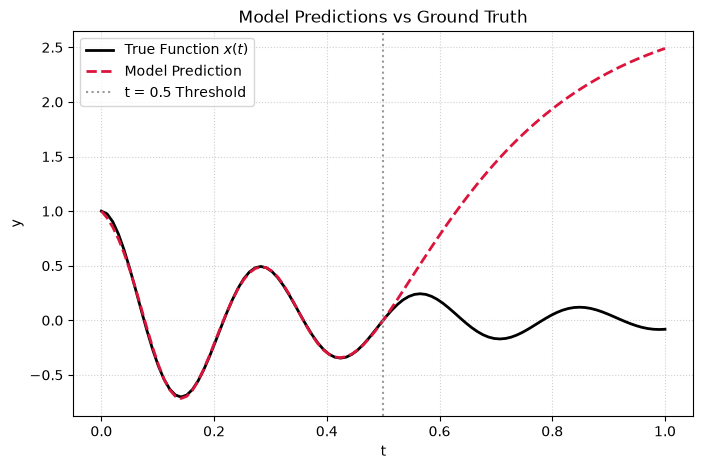

In [7]:
model.eval()

with torch.no_grad():
    t_test = torch.linspace(0, 1, 100).view(-1, 1)
    y_pred = model(t_test)
    y_true = x(t_test)

    print(t_test.shape,y_pred.shape, y_true.shape)


t_np = t_test.cpu().numpy()
y_pred_np = y_pred.cpu().numpy()
y_true_np = y_true.cpu().numpy()

# Initialize the plot
plt.figure(figsize=(8, 5))

# Plot the true values vs predictions
plt.plot(t_np, y_true_np, label='True Function $x(t)$', color='black', linewidth=2)
plt.plot(t_np, y_pred_np, label='Model Prediction', color='crimson', linestyle='--', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.8, label='t = 0.5 Threshold')

# Metadata & Styling
plt.title('Model Predictions vs Ground Truth')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


# Render
plt.show()





In [8]:
loss = criterion(y_pred, y_true)
print(f'Test Loss: {loss.item():.4f}')

Test Loss: 1.4870


## Task 2.3

In [9]:
net = Net().double()


In [ ]:

# data points and collocation points
t_data = np.linspace(0, 0.5, 10)
x_data = x(t_data)
t_col = np.linspace(0, 1, 50)

global lam_phys, lam_ic
lam_phys = 1e-4
lam_ic = 1

def NN(t, W1, b1, W2, b2):
    return np.sum(W2 * np.tanh(W1*t + b1)) + b2

def dNN(t, W1, b1, W2, b2):
    return np.sum(W2 * W1 * (1 - np.tanh(W1*t + b1)**2))

def ddNN(t, W1, b1, W2, b2):
    tanh = np.tanh(W1*t + b1)
    return np.sum(-2 * W2 * W1**2 * tanh * (1 - tanh**2))

def loss(W1, b1, W2, b2):
  # data term
  L_data = 0
  for i in range(len(t_data)):
      L_data += (NN(t_data[i], W1, b1, W2, b2) - x_data[i])**2
  L_data = L_data / len(t_data)

  # physics term
  L_phys = 0
  for i in range(len(t_col)):
      t = t_col[i]
      r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)
      L_phys += r**2
  L_phys = L_phys / len(t_col)

  # initial conditions
  L_ic = (NN(0, W1, b1, W2, b2) - 1)**2 + (dNN(0, W1, b1, W2, b2) - 0)**2
  return L_data + lam_phys*L_phys + lam_ic*L_ic

def gradients(W1, b1, W2, b2):
    
    dW1 = np.zeros(len(W1))
    db1 = np.zeros(len(b1))
    dW2 = np.zeros(len(W2))
    db2 = 0

    # data term
    for i in range(len(t_data)):
        t = t_data[i]
        tanh = np.tanh(W1*t + b1)
        e = NN(t, W1, b1, W2, b2) - x_data[i]

        dW1 += 2/len(t_data) * e * W2 * (1 - tanh**2) * t
        db1 += 2/len(t_data) * e * W2 * (1 - tanh**2)
        dW2 += 2/len(t_data) * e * tanh
        db2 += 2/len(t_data) * e

    # physics term
    for i in range(len(t_col)):
        t = t_col[i]
        tanh = np.tanh(W1*t + b1)
        r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)

        # eq (42)
        dr_dW1 = (-4 * W2 * W1 * tanh * (1 - tanh**2)
                  - 2 * W2 * W1**2 * t * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * t * tanh**2 * (1 - tanh**2)
                  + mu/m * (W2 * (1 - tanh**2) - 2 * W2 * W1 * t * tanh * (1 - tanh**2))
                  + k/m * W2 * t * (1 - tanh**2))

        # eq (43)
        dr_dW2 = (-2 * W1**2 * tanh * (1 - tanh**2)
                  + mu/m * W1 * (1 - tanh**2)
                  + k/m * tanh)

        # biases: same as for W1 but without the factor t from the inner derivative
        dr_db1 = (-2 * W2 * W1**2 * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * tanh**2 * (1 - tanh**2)
                  + mu/m * (-2 * W2 * W1 * tanh * (1 - tanh**2))
                  + k/m * W2 * (1 - tanh**2))
        dr_db2 = k/m

        dW1 += lam_phys * 2/len(t_col) * r * dr_dW1
        db1 += lam_phys * 2/len(t_col) * r * dr_db1
        dW2 += lam_phys * 2/len(t_col) * r * dr_dW2
        db2 += lam_phys * 2/len(t_col) * r * dr_db2

    # initial conditions (t = 0)
    tanh0 = np.tanh(b1)
    NN0 = NN(0, W1, b1, W2, b2)
    dNN0 = dNN(0, W1, b1, W2, b2)

    dW1 += lam_ic * 2 * dNN0 * W2 * (1 - tanh0**2)
    db1 += lam_ic * (2 * (NN0 - 1) * W2 * (1 - tanh0**2) - 4 * dNN0 * W2 * W1 * tanh0 * (1 - tanh0**2))
    dW2 += lam_ic * (2 * (NN0 - 1) * tanh0 + 2 * dNN0 * W1 * (1 - tanh0**2))
    db2 += lam_ic * 2 * (NN0 - 1)

    return dW1, db1, dW2, db2

## Task 2.4

In [11]:
epsilon = 10 ** -5

net = Net().double()
def get_params(model):
    W1 = model.net[0].weight.detach().numpy()[:, 0]
    b1 = model.net[0].bias.detach().numpy()
    W2 = model.net[2].weight.detach().numpy()[0, :]
    b2 = model.net[2].bias.detach().numpy()[0]
    return W1, b1, W2, b2
W1, b1, W2, b2 = get_params(net)

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2)

dW1_fd = np.zeros(len(W1))
for j in range(len(W1)):
    W1_minus = W1.copy()
    W1_minus[j] -= epsilon
    W1_plus = W1.copy()
    W1_plus[j] += epsilon
    dW1_fd[j] = (loss(W1_plus, b1, W2, b2) - loss(W1_minus, b1, W2, b2)) / (2*epsilon)

print(dW1)
print(dW1_fd)
print(" error:", np.linalg.norm(dW1 - dW1_fd) / np.linalg.norm(dW1_fd))

[ 0.75575061  0.93745194 -1.36207686 -0.16028473 -1.49467128 -3.36918004
  2.41833512  0.34286151  1.82905068 -0.10940948]
[ 0.75575061  0.93745194 -1.36207686 -0.16028473 -1.49467128 -3.36918004
  2.41833512  0.34286151  1.82905068 -0.10940948]
 error: 3.5281572100073244e-11


## Task 2.5


### Hyperparameter tuning (Lambda values)

In [28]:
# Our settings for the sweep (20000 for final pass)
torch.set_default_dtype(torch.double)

adam_epochs = 3000
lbfgs_iter = 5000   
SEEDS = [0, 1]
# Logarithmic spacing from 10^-5 to 10^-2
LAM_PHYS_GRID = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
# Logarithmic spacing from 10^-1.5 (≈0.03) to 10^0 (1.0), with 0 prepended
LAM_IC_GRID = [0, 0.03, 0.1, 0.3, 1]

OPTIMIZERS = ["Adam","LBFGS","Adam+LBFGS"]

# Load the data for the sweep
t_eval = torch.linspace(0, 2, 100).view(-1, 1)
x_eval = x(t_eval)
mask_extrap = (t_eval[:, 0] > 0.5)

def train(lam_p, lam_i, seed, optim, final=False):
    # settings for each run
    lam_phys, lam_ic = lam_p, lam_i
    torch.manual_seed(seed)
    model = Net().double()      

    def closure():
        # Loss function  where the forward pass also happens
        W1, b1, W2, b2 = get_params(model)
        L = loss(W1, b1, W2, b2)

        # Update weights
        dW1,db1, dW2, db2= gradients(W1,b1,W2,b2) # compute gradient

        # Our parameters are converted in torch again, in order to use the ADAM Optimizer.
        model.net[0].weight.grad = torch.tensor(dW1).reshape(10, 1)
        model.net[0].bias.grad = torch.tensor(db1)
        model.net[2].weight.grad = torch.tensor(dW2).reshape(1, 10)
        model.net[2].bias.grad = torch.tensor([db2])
        return torch.tensor(L)
    
    losses = []

    if optim == "Adam" or optim == "Adam+LBFGS":
        if final:
            adam_epochs  = 10000
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        for i in range(adam_epochs):
            L = closure()
            losses.append(L)
            optimizer.step()
            
            if i % 1000 == 0:
                print(i, losses[-1])

    if optim == "LBFGS" or optim == "Adam+LBFGS":
        if final:
            lbfgs_iter = 10000
        optimizer = torch.optim.LBFGS(  model.parameters(),
                                        lr=1.0,
                                        max_iter=lbfgs_iter,
                                        max_eval=1.5*lbfgs_iter,
                                        tolerance_grad=1e-10,
                                        tolerance_change=1e-14,
                                        history_size=50,
                                        line_search_fn="strong_wolfe",
                                    )
        optimizer.step(closure)
        losses.append(closure().item())
        print("LBFGS optimized:", losses[-1])
            
    with torch.no_grad():
        err = (model(t_eval) - x_eval) ** 2
        return model, err.mean().item(), err[mask_extrap].mean().item()



C:\Users\agrim\AppData\Local\Temp\ipykernel_8332\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


In [26]:
# The sweep to check all combinations
results = []
for lp, li in itertools.product(LAM_PHYS_GRID, LAM_IC_GRID):
    runs = [train(lp, li, s,OPTIMIZERS[2])[1:] for s in SEEDS]
    full = np.array([r[0] for r in runs])
    extrap = np.array([r[1] for r in runs])
    results.append((lp, li, np.median(full), full.max(), np.median(extrap)))
    print(f"lam_phys={lp:<7g} lam_ic={li:<5g} "
          f"median_full={np.median(full):.3e} worst={full.max():.3e} "
          f"median_extrap={np.median(extrap):.3e}", flush=True)

results.sort(key=lambda r: r[2])
print("\nTop 5 (lam_phys, lam_ic, median_full_MSE, worst_MSE, median_extrap_MSE):")
for r in results[:5]:
    print(f"  {r[0]:<7g} {r[1]:<5g} {r[2]:.3e} {r[3]:.3e} {r[4]:.3e}")

0 tensor(1.1435)
1000 tensor(0.3203)
2000 tensor(0.1332)
LBFGS optimized: 0.0013927639269709548
0 tensor(9.5949)
1000 tensor(1.0753)
2000 tensor(0.9079)
LBFGS optimized: 0.003000506468903437
lam_phys=1e-05   lam_ic=0     median_full=6.620e+00 worst=1.324e+01 median_extrap=8.827e+00
0 tensor(1.1435)
1000 tensor(0.3203)
2000 tensor(0.1332)
LBFGS optimized: 0.0013927639269709548
0 tensor(9.5949)
1000 tensor(1.0753)
2000 tensor(0.9079)
LBFGS optimized: 0.003000506468903437
lam_phys=1e-05   lam_ic=0.03  median_full=6.620e+00 worst=1.324e+01 median_extrap=8.827e+00
0 tensor(1.1435)
1000 tensor(0.3203)
2000 tensor(0.1332)
LBFGS optimized: 0.0013927639269709548
0 tensor(9.5949)
1000 tensor(1.0753)
2000 tensor(0.9079)
LBFGS optimized: 0.003000506468903437
lam_phys=1e-05   lam_ic=0.1   median_full=6.620e+00 worst=1.324e+01 median_extrap=8.827e+00
0 tensor(1.1435)
1000 tensor(0.3203)
2000 tensor(0.1332)
LBFGS optimized: 0.0013927639269709548
0 tensor(9.5949)
1000 tensor(1.0753)
2000 tensor(0.9079

In [36]:
from itertools import groupby
import seaborn as sns
import matplotlib.colors as mcolors

# Plot our best lambdas
results.sort(key=lambda r: r[2])
best_lp, best_li = results[0][0], 1
net, full, extrap = train(best_lp, best_li, seed=SEEDS[0], optim=OPTIMIZERS[2], final=True)
with torch.no_grad():
    pred = net(t_eval)


lam_ic =  1
lam_phys =  0.0001
0 tensor(1.1435)
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =  0.0001
lam_ic =  1
lam_phys =

KeyboardInterrupt: 

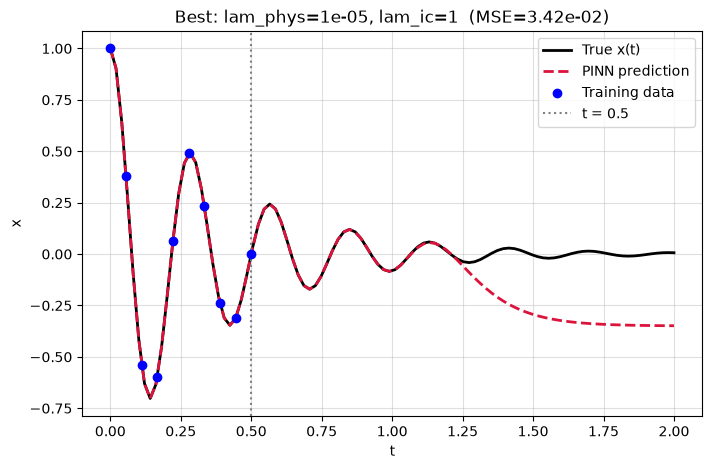

<Axes: >

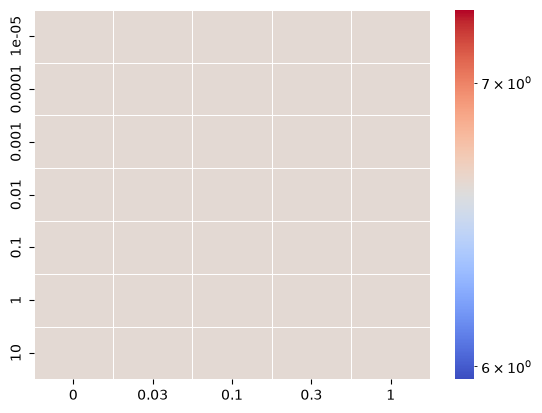

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(t_eval, x_eval, "k", lw=2, label="True x(t)")
plt.plot(t_eval, pred, "--", color="crimson", lw=2, label="PINN prediction")
plt.scatter(t_data, x_data, color="blue", zorder=3, label="Training data")
plt.axvline(0.5, color="gray", ls=":", label="t = 0.5")
plt.title(f"Best: lam_phys={best_lp:g}, lam_ic={best_li:g}  (MSE={full:.2e})")
plt.xlabel("t"); plt.ylabel("x"); plt.legend(); plt.grid(alpha=0.4)
plt.show()

# Heatmap of lambdas
results.sort(key=lambda r: r[1])
results.sort(key=lambda r: r[0])

x1 = sorted(set([i[0] for i in results]))
x2 = sorted(set([i[1] for i in results]))
y = [[c for _, _, c,_,_ in group] for _, group in groupby(results, key=lambda item: item[0])]

sns.heatmap(
    y, 
    xticklabels=x2,  # Custom x-axis labels
    yticklabels=x1,  # Hide y-axis labels
    norm=mcolors.LogNorm(),  # Logarithmic scaling
    cmap="coolwarm",  # Color map
    linewidths=0.5  # Cell spacing
)

In [ ]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    outputs = model(t_train)
    loss =
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {loss.item():.4f}')

